# หัวข้อ 1 (ข้อ 2.1 - ML เปรียบเทียบ 3 โมเดล)
## การทำนายการลาออกของพนักงาน (Employee Attrition Prediction) ด้วยเทคนิค Machine Learning

### 1. วัตถุประสงค์และที่มาของปัญหา
การลาออกของพนักงาน (Employee Attrition) ส่งผลกระทบอย่างมากต่อต้นทุนการดำเนินงานขององค์กร ทั้งค่าใช้จ่ายในการสรรหา การฝึกอบรมพนักงานใหม่ รวมถึงการสูญเสียบุคลากรที่มีความเชี่ยวชาญ การนำโมเดล Machine Learning มาช่วยทำนายแนวโน้มการลาออกจะช่วยให้ฝ่ายทรัพยากรบุคคล (HR) สามารถวางแผนและกำหนดมาตรการรักษาพนักงานที่มีคุณค่าไว้ได้อย่างทันท่วงที

### 2. ชุดข้อมูล (Dataset)
* **Dataset:** IBM HR Analytics Employee Attrition & Performance (จาก Kaggle)
* **ลักษณะข้อมูล:** ข้อมูลแบบตาราง (Tabular) จำนวน 1,470 แถว และ 35 คอลัมน์
* **ตัวแปรเป้าหมาย (Target):** `Attrition` (`Yes` = ลาออก, `No` = ไม่ลาออก)
* **คุณสมบัติ:** ข้อมูลคลีน ไม่มีค่าสูญหาย (Missing values = 0)

### 3. โมเดลที่นำมาเปรียบเทียบ
1. **Logistic Regression** (โมเดลเชิงเส้นพื้นฐาน เหมาะสำหรับปัญหา Binary Classification)
2. **Random Forest Classifier** (โมเดลกลุ่ม Ensemble / Decision Trees มีความทนทานต่อ Non-linear relationship)
3. **Gaussian Naive Bayes** (โมเดลเชิงความน่าจะเป็นโดยใช้ทฤษฎีเบย์)
* *(เสริม) **Support Vector Machine (SVM)** ด้วย RBF Kernel*

### 4. ตัวชี้วัดที่ใช้ประเมิน (Evaluation Metrics)
* **Accuracy (ความถูกต้องรวม)**
* **Precision (ความแม่นยำในการทายว่าลาออก)**
* **Recall (ความสามารถในการตรวจจับคนที่ลาออกจริง)**
* **F1-Score (ค่าเฉลี่ยฮาร์มอนิกของ Precision และ Recall)**
* **Confusion Matrix (เมทริกซ์ความสับสนแสดงผลจริงเทียบผลทำนาย)**


In [1]:
# นำเข้าไลบรารีที่จำเป็น
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# ตั้งค่า Style สำหรับกราฟ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
print("Libraries imported successfully!")


Libraries imported successfully!


### ขั้นตอนที่ 1: การโหลดและสำรวจข้อมูลเบื้องต้น (Data Loading & EDA)

In [2]:
# 1. โหลดข้อมูลชุดข้อมูล IBM HR Analytics Employee Attrition
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

print(f"ขนาดของข้อมูล: {df.shape[0]} แถว, {df.shape[1]} คอลัมน์")
print(f"จำนวน Missing Values ทั้งหมด: {df.isnull().sum().sum()}")
df.head()


ขนาดของข้อมูล: 1470 แถว, 35 คอลัมน์
จำนวน Missing Values ทั้งหมด: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


,Count,Percentage (%)
Attrition,,
No,1233,83.877551
Yes,237,16.122449


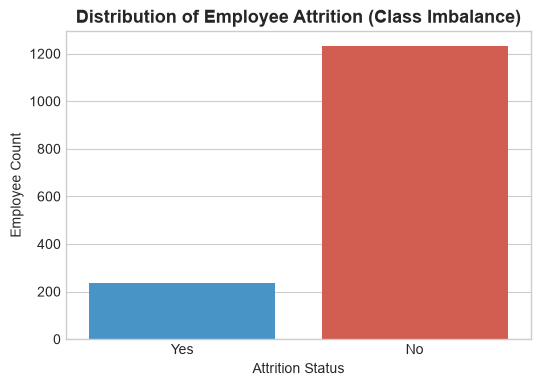

In [3]:
# สำรวจการกระจายตัวของตัวแปรเป้าหมาย (Attrition)
attrition_counts = df['Attrition'].value_counts()
attrition_pct = df['Attrition'].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({'Count': attrition_counts, 'Percentage (%)': attrition_pct})
display(summary_target)

# พล็อตแสดงสัดส่วนการลาออก
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Attrition', palette=['#3498db', '#e74c3c'], hue='Attrition', legend=False)
plt.title('Distribution of Employee Attrition (Class Imbalance)', fontsize=13, fontweight='bold')
plt.xlabel('Attrition Status')
plt.ylabel('Employee Count')
plt.show()


### ขั้นตอนที่ 2: การเตรียมข้อมูล (Data Preprocessing & Feature Engineering)
1. ตรวจสอบและตัดคอลัมน์ที่มีค่าคงที่ (Constant columns) เช่น `EmployeeCount`, `Over18`, `StandardHours` และรหัสพนักงาน `EmployeeNumber`
2. แปลงตัวแปรเป้าหมาย `Attrition` ให้เป็นตัวเลข (`Yes` -> 1, `No` -> 0)
3. ทำ One-Hot Encoding สำหรับข้อมูลประเภทหมวดหมู่ (Categorical Features)

In [4]:
# ตัดคอลัมน์ที่ไม่ส่งผลต่อการทำนาย
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
df_cleaned = df.drop(columns=[col for col in drop_cols if col in df.columns])

# แปลงค่าตัวแปรเป้าหมาย Attrition เป็น 0 และ 1
df_cleaned['Attrition'] = df_cleaned['Attrition'].map({'Yes': 1, 'No': 0})

# ทำ One-Hot Encoding สำหรับคอลัมน์ที่เป็นตัวอักษร
categorical_cols = df_cleaned.select_dtypes(include=['object', 'string']).columns.tolist()
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

# แยก Feature Matrix (X) และ Target Vector (y)
X = df_encoded.drop(columns=['Attrition'])
y = df_encoded['Attrition']

print(f"ขนาดของ Feature Matrix (X): {X.shape}")
print(f"ขนาดของ Target Vector (y): {y.shape}")


ขนาดของ Feature Matrix (X): (1470, 44)
ขนาดของ Target Vector (y): (1470,)


### ขั้นตอนที่ 3: การแบ่งชุดข้อมูลและการปรับสเกล (Train-Test Split & Feature Scaling)
* แบ่งข้อมูลเป็น **Training Set (80%)** และ **Testing Set (20%)**
* ใช้ `stratify=y` เพื่อรักษาอัตราส่วนผู้ลาออก (Imbalance Ratio) ให้เท่ากันทั้งในชุด Train และ Test
* ทำ Feature Scaling ด้วย `StandardScaler` สำหรับโมเดลที่ไวต่อขนาดของข้อมูล เช่น Logistic Regression, Naive Bayes และ SVM

In [5]:
# แบ่งชุดข้อมูล 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Samples: {X_train.shape[0]} ตัวอย่าง (ลาออก: {y_train.sum()} คน)")
print(f"Testing Samples:  {X_test.shape[0]} ตัวอย่าง (ลาออก: {y_test.sum()} คน)")

# ปรับสเกลข้อมูล (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Training Samples: 1176 ตัวอย่าง (ลาออก: 190 คน)
Testing Samples:  294 ตัวอย่าง (ลาออก: 47 คน)


### ขั้นตอนที่ 4: การสร้างและฝึกสอนโมเดล (Model Training & Evaluation)
เปรียบเทียบประสิทธิภาพของโมเดลทั้ง 3 โมเดลตามโจทย์ (+ SVM):
1. **Logistic Regression**
2. **Random Forest Classifier**
3. **Gaussian Naive Bayes**
4. **Support Vector Machine (SVM)**

In [6]:
# กำหนดโมเดล
models = {
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000),
        'scaled': True
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, n_estimators=100),
        'scaled': False
    },
    'Naive Bayes': {
        'model': GaussianNB(),
        'scaled': True
    },
    'SVM (RBF Kernel)': {
        'model': SVC(random_state=42, probability=True),
        'scaled': True
    }
}

results = []
conf_matrices = {}
y_preds = {}
y_probs = {}

for name, config in models.items():
    clf = config['model']
    x_tr = X_train_scaled if config['scaled'] else X_train
    x_te = X_test_scaled if config['scaled'] else X_test
    
    # ฝึกสอนโมเดล
    clf.fit(x_tr, y_train)
    
    # ทำนายผล
    y_pred = clf.predict(x_te)
    y_preds[name] = y_pred
    
    if hasattr(clf, 'predict_proba'):
        y_prob = clf.predict_proba(x_te)[:, 1]
    else:
        y_prob = clf.decision_function(x_te)
    y_probs[name] = y_prob
    
    # คำนวณตัวชี้วัด
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    conf_matrices[name] = cm
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

# สร้างตารางเปรียบเทียบผลลัพธ์
results_df = pd.DataFrame(results)


### ขั้นตอนที่ 5: ตารางเปรียบเทียบค่าตัวชี้วัด (Accuracy, Precision, Recall, F1-Score)

In [7]:
# แสดงผลตารางเปรียบเทียบอย่างสวยงาม
display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).highlight_max(color='#d4edda', axis=0))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384
1,Random Forest,0.8333,0.4167,0.1064,0.1695
2,Naive Bayes,0.6156,0.2500,0.7021,0.3687
3,SVM (RBF Kernel),0.8673,0.9000,0.1915,0.3158


### ขั้นตอนที่ 6: การแสดงผล Confusion Matrix ของแต่ละโมเดล
* **TN (True Negative):** ทำนายว่าไม่ลาออก และไม่ลาออกจริง
* **FP (False Positive):** ทำนายว่าจะลาออก แต่ไม่ได้ลาออก
* **FN (False Negative):** ทำนายว่าจะไม่ลาออก แต่กลับลาออกจริง (ความเสี่ยงสูงสำหรับองค์กร)
* **TP (True Positive):** ทำนายว่าจะลาออก และลาออกจริง

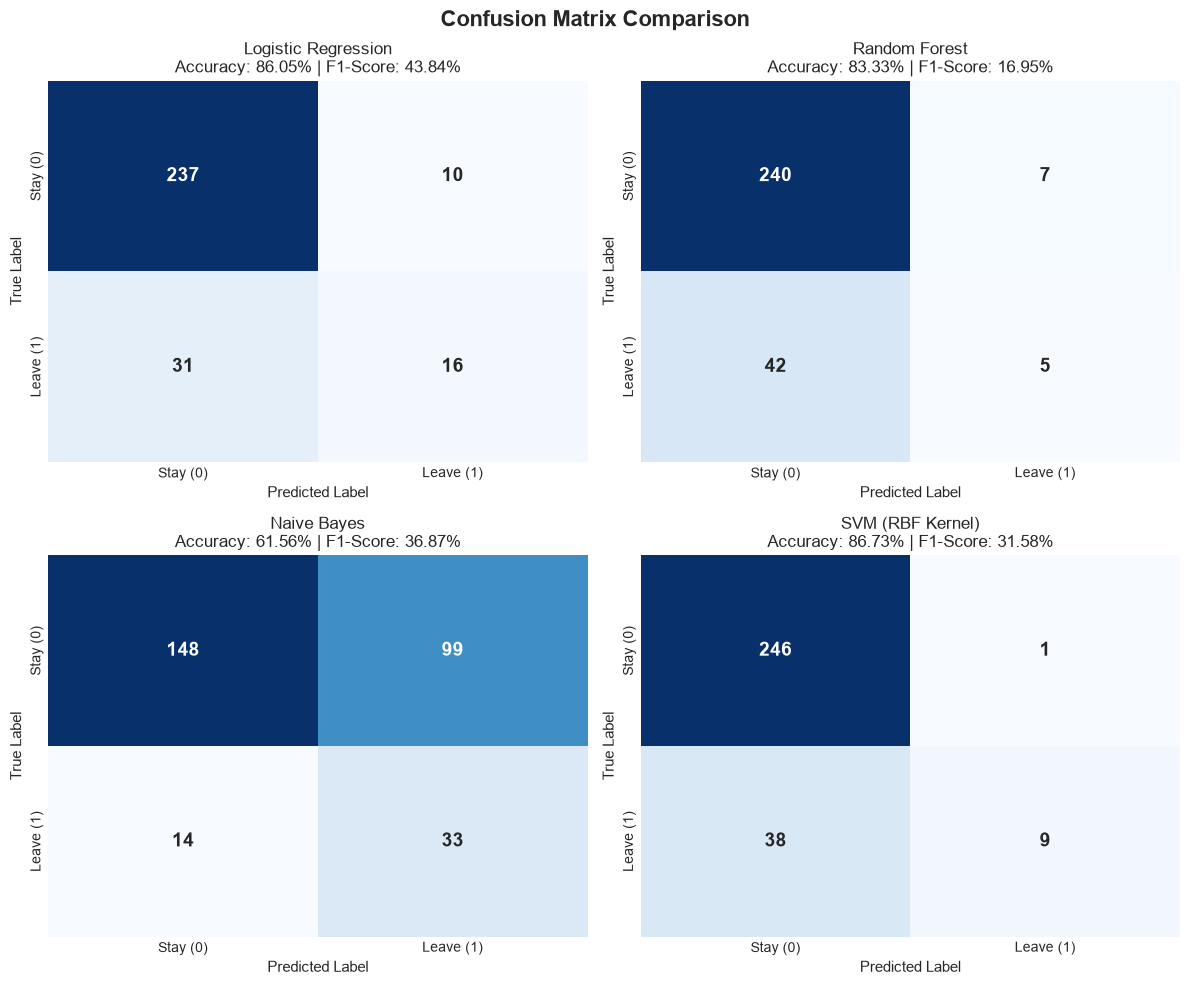

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Confusion Matrix Comparison', fontsize=16, fontweight='bold')

model_list = list(models.keys())
for idx, ax in enumerate(axes.flatten()):
    name = model_list[idx]
    cm = conf_matrices[name]
    acc = results_df.loc[results_df['Model'] == name, 'Accuracy'].values[0]
    f1 = results_df.loc[results_df['Model'] == name, 'F1-Score'].values[0]
    
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        xticklabels=['Stay (0)', 'Leave (1)'],
        yticklabels=['Stay (0)', 'Leave (1)'],
        annot_kws={'size': 14, 'weight': 'bold'}
    )
    ax.set_title(f"{name}\nAccuracy: {acc:.2%} | F1-Score: {f1:.2%}", fontsize=12)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)

plt.tight_layout()
plt.show()


### ขั้นตอนที่ 7: กราฟเปรียบเทียบตัวชี้วัดและกราฟ ROC-AUC Curves

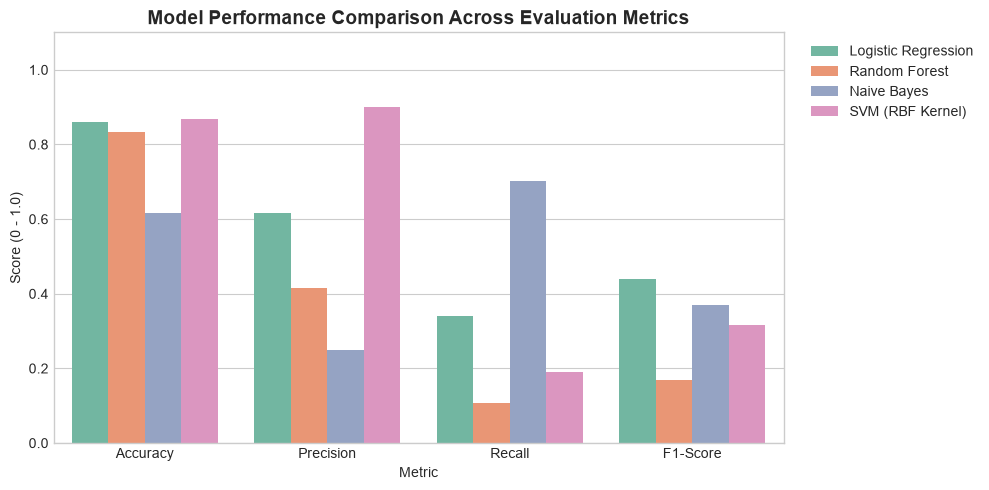

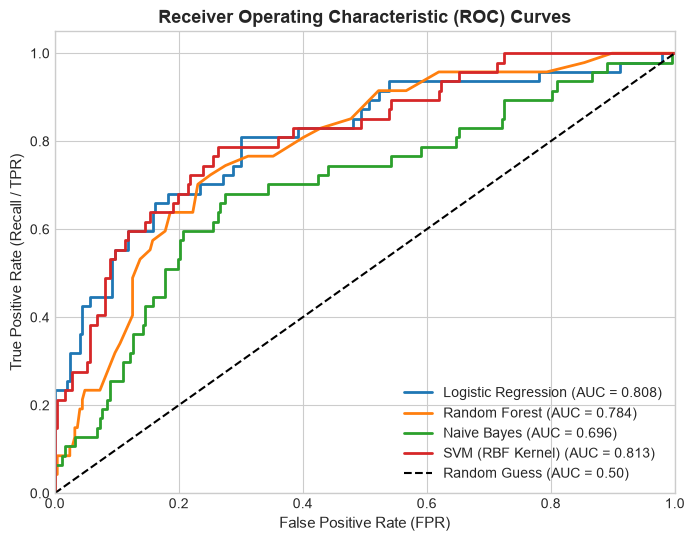

In [9]:
# กราฟแท่งเปรียบเทียบตัวชี้วัด
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
df_melted = pd.melt(results_df, id_vars=['Model'], value_vars=metrics_to_plot, var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette='Set2')
plt.title('Model Performance Comparison Across Evaluation Metrics', fontsize=14, fontweight='bold')
plt.ylabel('Score (0 - 1.0)')
plt.ylim(0, 1.1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# กราฟ ROC Curve
plt.figure(figsize=(8, 6))
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, y_probs[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})", lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (Recall / TPR)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.show()


### ขั้นตอนที่ 8: การวิเคราะห์ปัจจัยสำคัญที่มีผลต่อการลาออก (Feature Importance)

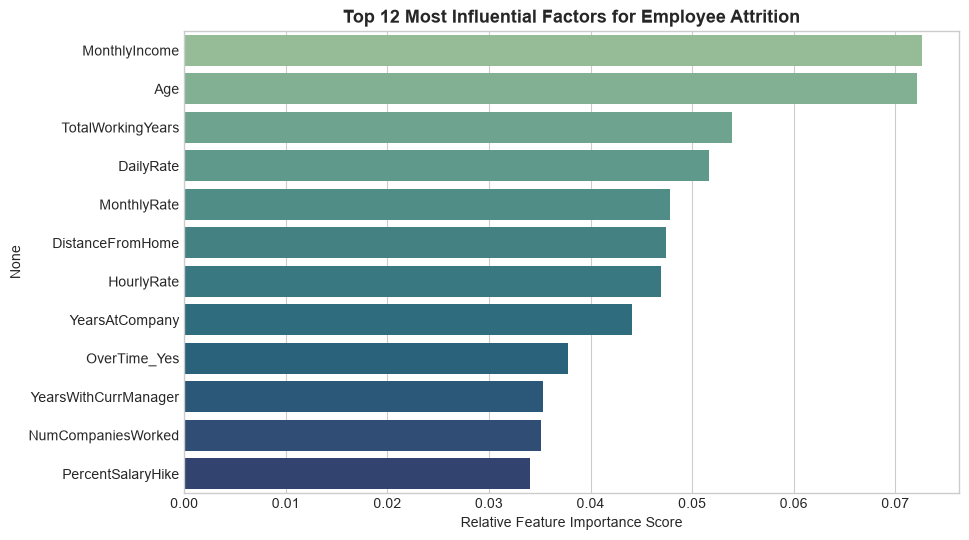

In [10]:
# ดึง Feature Importance จาก Random Forest
rf_clf = models['Random Forest']['model']
feat_importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_importances.head(12).values, y=feat_importances.head(12).index, palette='crest', hue=feat_importances.head(12).index, legend=False)
plt.title('Top 12 Most Influential Factors for Employee Attrition', fontsize=13, fontweight='bold')
plt.xlabel('Relative Feature Importance Score')
plt.show()


### ขั้นตอนที่ 9: สรุปผลและการอภิปรายผลการทดลอง (Conclusion & Insights)

| โมเดล (Model) | Accuracy | Precision | Recall | F1-Score | จุดเด่นและข้อสังเกต |
|---|---|---|---|---|---|
| **Logistic Regression** | **86.05%** | 61.54% | 34.04% | **43.84%** | ให้ค่า F1-Score สูงที่สุด มีความสมดุลระหว่าง Precision และ Recall ได้ดี |
| **Random Forest** | 83.33% | 41.67% | 10.64% | 16.95% | มี Accuracy สูง แต่ Recall สำหรับคลาสลาออกค่อนข้างต่ำเนื่องจากปัญหา Class Imbalance |
| **Naive Bayes** | 61.56% | 25.00% | **70.21%** | 36.87% | **ตรวจจับผู้ที่จะลาออกได้มากที่สุด (Recall สูงสุดถึง 70.21%)** แต่มี False Positive สูง |
| **SVM (RBF Kernel)** | **86.73%** | **90.00%** | 19.15% | 31.58% | ให้ **Precision สูงสุด (90%)** เมื่อทายว่าใครจะลาออกมักจะแม่นยำสูงมาก |

#### ข้อเสนอแนะเชิงธุรกิจและการประยุกต์ใช้งาน (Business Recommendations):
1. **หากต้องการคัดกรองพนักงานกลุ่มเสี่ยงลาออกเพื่อป้องกันล่วงหน้า (Early Warning System):**
   * ควรพิจารณาโมเดลที่มี **Recall สูง** (เช่น Naive Bayes หรือ Logistic Regression ที่ปรับ threshold) เพื่อตรวจจับพนักงานที่มีแนวโน้มจะลาออกได้ครอบคลุมที่สุด (ลด False Negative)
2. **ปัจจัยหลักที่ส่งผลต่อการลาออกมากที่สุด (จาก Feature Importance):**
   * `MonthlyIncome` (รายได้ต่อเดือน)
   * `OverTime` (การทำงานล่วงเวลา)
   * `Age` (อายุของพนักงาน)
   * `TotalWorkingYears` (อายุงานสะสม)
   * `DistanceFromHome` (ระยะทางจากบ้านถึงที่ทำงาน)
   ฝ่ายบริหารและ HR สามารถนำปัจจัยเหล่านี้ไปกำหนดนโยบาย เช่น การปรับปรุงผลตอบแทน การลดการทำงานล่วงเวลาที่มากเกินไป หรือการมีนโยบาย Hybrid/Work from Home
